# Final Comparative Analysis — ASSISTments 2009–2010 vs ASSISTments 2015

## Two datasets × four machine-learning models

This notebook consolidates the **saved outputs from the two final executed project notebooks**. It compares Bayesian Knowledge Tracing (BKT), Logistic Regression, Decision Tree, and Random Forest across both datasets.

**Important:** This is a results-comparison notebook. It does not retrain the models. The values below are transcribed from the executed evaluation outputs of the two supplied notebooks, so the original experiments remain unchanged.

## 1. Project objectives

- Compare four models on ASSISTments 2009–2010.
- Compare the same four model families on ASSISTments 2015.
- Compare accuracy, precision, recall, F1-score, ROC-AUC, Brier score, and log loss.
- Discuss dataset and experimental differences before drawing conclusions.

## 2. Dataset overview

| Characteristic | ASSISTments 2009–2010 | ASSISTments 2015 |
|---|---:|---:|
| Original interactions | 346,860 | 708,631 |
| Students in original file | 4,163 after cleaning | 19,917 before partial-credit exclusion |
| Rows used in modelling | 283,105 | 683,801 |
| Students retained for modelling | 4,163 | 19,840 |
| Skill/sequence information | `skill_id` available | 100 `sequence_id` values; no explicit skill column in supplied file |
| Target | Binary `correct` | Exact binary 0/1 rows; 24,830 partial-credit rows excluded |
| Test interactions | 57,213 | 132,708 |

Dataset 1 uses student–skill sequences. Dataset 2 uses student–`sequence_id` sequences as a proxy because the supplied CSV has no separate skill identifier. These are related but not identical experimental settings.

## 3. Results captured from the final notebooks

The following table contains the actual saved evaluation metrics from the two executed notebooks. Scores are shown as decimals except Accuracy, Precision, Recall, and F1-score, which are converted to percentages for readability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

records = [
    {"Dataset":"ASSISTments 2009–2010", "Model":"BKT", "Accuracy":0.701799, "Precision":0.711318, "Recall":0.919896, "F1 Score":0.802272, "ROC-AUC":0.679553, "Brier Score":0.201661, "Log Loss":0.591409},
    {"Dataset":"ASSISTments 2009–2010", "Model":"Logistic Regression", "Accuracy":0.662175, "Precision":0.783163, "Recall":0.672514, "F1 Score":0.723633, "ROC-AUC":0.713596, "Brier Score":0.213244, "Log Loss":0.615779},
    {"Dataset":"ASSISTments 2009–2010", "Model":"Decision Tree", "Accuracy":0.641113, "Precision":0.781886, "Recall":0.630043, "F1 Score":0.697800, "ROC-AUC":0.703698, "Brier Score":0.213927, "Log Loss":0.644081},
    {"Dataset":"ASSISTments 2009–2010", "Model":"Random Forest", "Accuracy":0.659990, "Precision":0.783254, "Recall":0.667783, "F1 Score":0.720924, "ROC-AUC":0.722377, "Brier Score":0.211931, "Log Loss":0.613213},
    {"Dataset":"ASSISTments 2015", "Model":"BKT", "Accuracy":0.7412439340506978, "Precision":0.7491125003926989, "Recall":0.9755049859371004, "F1 Score":0.8474493445106376, "ROC-AUC":0.6496253910113192, "Brier Score":0.18247280655607206, "Log Loss":0.5476107984479941},
    {"Dataset":"ASSISTments 2015", "Model":"Logistic Regression", "Accuracy":0.6271362691020888, "Precision":0.8359232620581238, "Recall":0.614543594988494, "F1 Score":0.7083392276135239, "ROC-AUC":0.6880233863761247, "Brier Score":0.22257974578549372, "Log Loss":0.6346675029092054},
    {"Dataset":"ASSISTments 2015", "Model":"Decision Tree", "Accuracy":0.6283645296440306, "Precision":0.8313185460711648, "Recall":0.6217437995397597, "F1 Score":0.7114177213708521, "ROC-AUC":0.6832293192177366, "Brier Score":0.22211486423921337, "Log Loss":0.6343005404230903},
    {"Dataset":"ASSISTments 2015", "Model":"Random Forest", "Accuracy":0.6343852669017693, "Precision":0.8347173709175422, "Recall":0.6281360265916646, "F1 Score":0.7168401886175825, "ROC-AUC":0.6949259261783102, "Brier Score":0.22435937245367185, "Log Loss":0.6399468538536642}
]
results = pd.DataFrame(records)
metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "Brier Score", "Log Loss"]
display(results.style.format({c:"{:.4f}" for c in metric_cols}).highlight_max(subset=["Accuracy","Precision","Recall","F1 Score","ROC-AUC"], color="#d9ead3").highlight_min(subset=["Brier Score","Log Loss"], color="#d9ead3"))

,Dataset,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score,Log Loss
0,ASSISTments 2009–2010,BKT,0.7018,0.7113,0.9199,0.8023,0.6796,0.2017,0.5914
1,ASSISTments 2009–2010,Logistic Regression,0.6622,0.7832,0.6725,0.7236,0.7136,0.2132,0.6158
2,ASSISTments 2009–2010,Decision Tree,0.6411,0.7819,0.6300,0.6978,0.7037,0.2139,0.6441
3,ASSISTments 2009–2010,Random Forest,0.6600,0.7833,0.6678,0.7209,0.7224,0.2119,0.6132
4,ASSISTments 2015,BKT,0.7412,0.7491,0.9755,0.8474,0.6496,0.1825,0.5476
5,ASSISTments 2015,Logistic Regression,0.6271,0.8359,0.6145,0.7083,0.6880,0.2226,0.6347
6,ASSISTments 2015,Decision Tree,0.6284,0.8313,0.6217,0.7114,0.6832,0.2221,0.6343
7,ASSISTments 2015,Random Forest,0.6344,0.8347,0.6281,0.7168,0.6949,0.2244,0.6399


## 4. Compare accuracy and F1-score

Accuracy measures the proportion of correct class predictions. F1-score balances precision and recall. Both are useful, but neither should be interpreted alone.

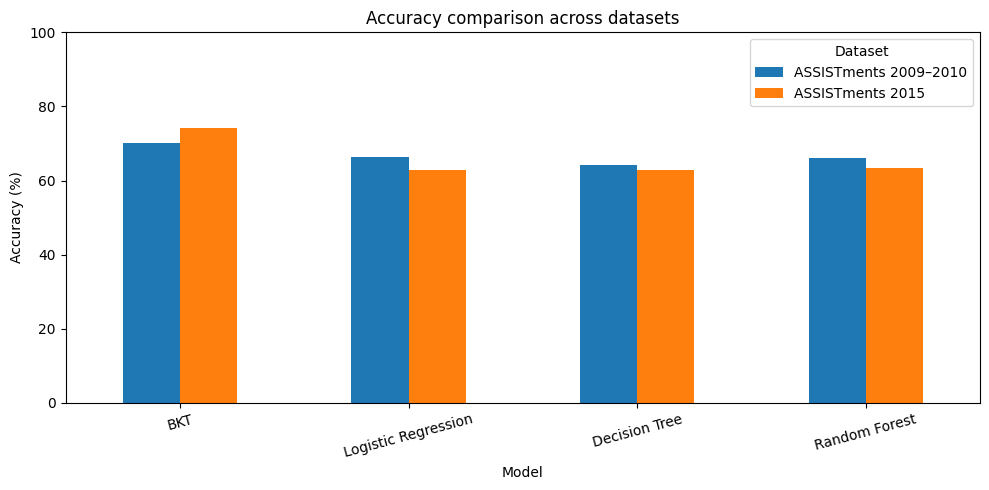

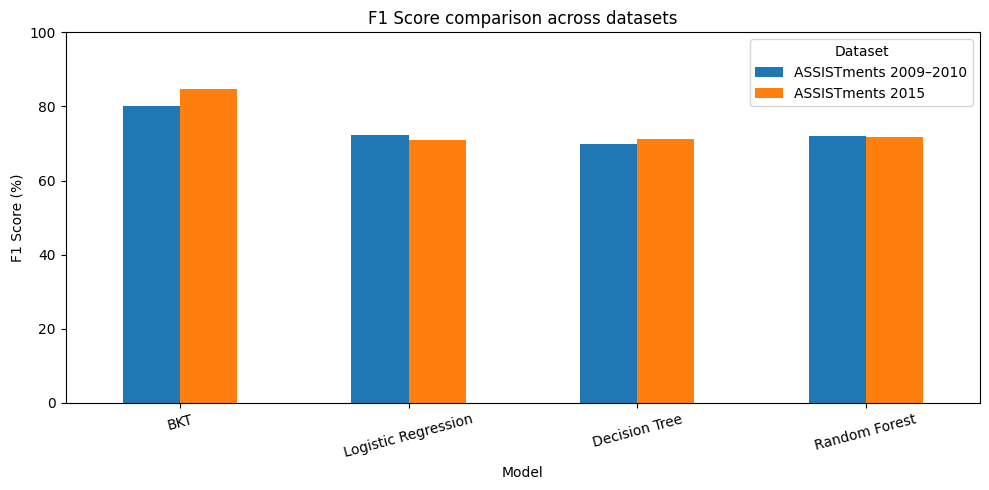

In [2]:
model_order = ["BKT", "Logistic Regression", "Decision Tree", "Random Forest"]
datasets = ["ASSISTments 2009–2010", "ASSISTments 2015"]
for metric in ["Accuracy", "F1 Score"]:
    pivot = results.pivot(index="Model", columns="Dataset", values=metric).reindex(model_order) * 100
    ax = pivot.plot(kind="bar", figsize=(10,5))
    ax.set_title(f"{metric} comparison across datasets")
    ax.set_ylabel(f"{metric} (%)")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 5. Compare ROC-AUC

ROC-AUC evaluates ranking/discrimination across classification thresholds. A higher value indicates better separation between the two response classes.

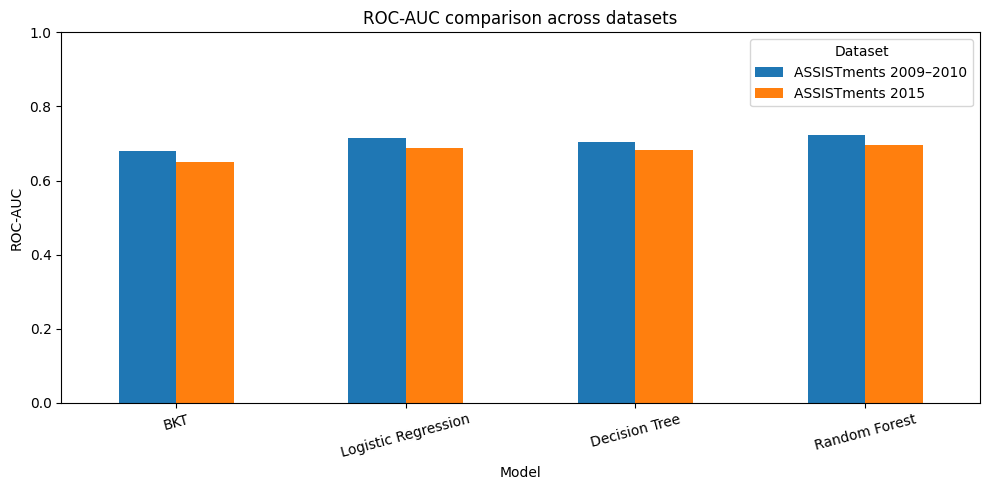

In [3]:
pivot_auc = results.pivot(index="Model", columns="Dataset", values="ROC-AUC").reindex(model_order)
ax = pivot_auc.plot(kind="bar", figsize=(10,5))
ax.set_title("ROC-AUC comparison across datasets")
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Compare probability-quality metrics

Brier score and log loss evaluate predicted probabilities rather than only the final class labels. **Lower values are better** for both metrics.

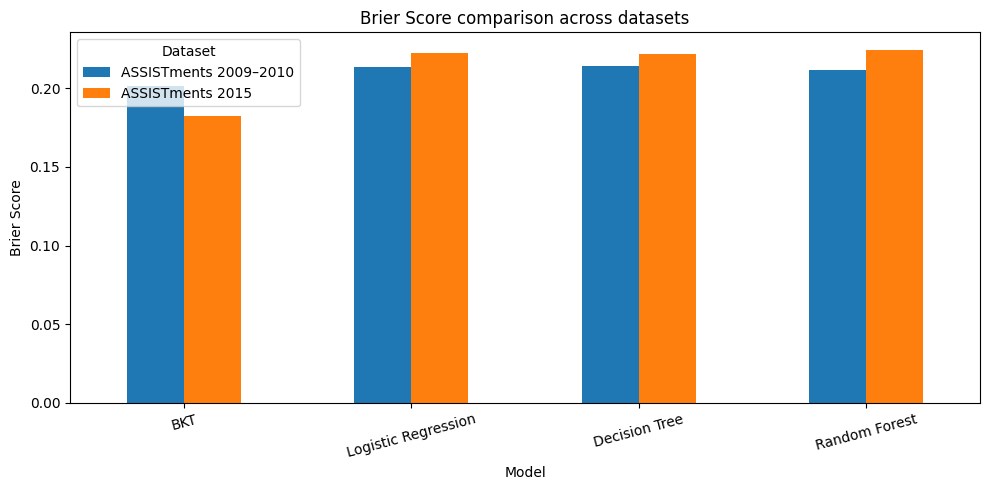

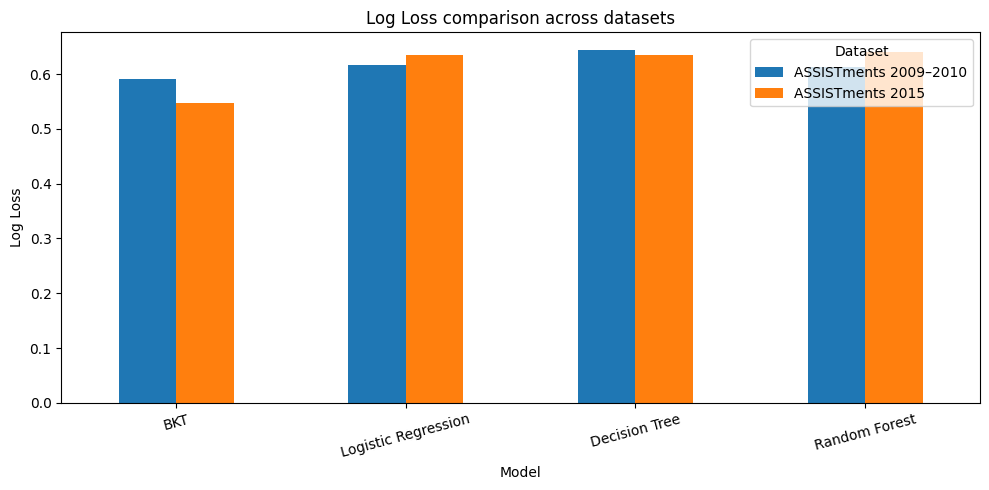

In [4]:
for metric in ["Brier Score", "Log Loss"]:
    pivot = results.pivot(index="Model", columns="Dataset", values=metric).reindex(model_order)
    ax = pivot.plot(kind="bar", figsize=(10,5))
    ax.set_title(f"{metric} comparison across datasets")
    ax.set_ylabel(metric)
    ax.set_xlabel("Model")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 7. Best model within each dataset

The table below identifies the highest value for metrics where higher is better and the lowest value for metrics where lower is better. This is a metric-wise comparison, not a single universal winner.

In [5]:
higher_is_better = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
lower_is_better = ["Brier Score", "Log Loss"]
summary = []
for dataset in datasets:
    subset = results[results["Dataset"] == dataset]
    row = {"Dataset": dataset}
    for metric in higher_is_better:
        best = subset.loc[subset[metric].idxmax()]
        row[metric + " leader"] = f"{best['Model']} ({best[metric]:.4f})"
    for metric in lower_is_better:
        best = subset.loc[subset[metric].idxmin()]
        row[metric + " leader"] = f"{best['Model']} ({best[metric]:.4f})"
    summary.append(row)
display(pd.DataFrame(summary).T)

,0,1
Dataset,ASSISTments 2009–2010,ASSISTments 2015
Accuracy leader,BKT (0.7018),BKT (0.7412)
Precision leader,Random Forest (0.7833),Logistic Regression (0.8359)
Recall leader,BKT (0.9199),BKT (0.9755)
F1 Score leader,BKT (0.8023),BKT (0.8474)
ROC-AUC leader,Random Forest (0.7224),Random Forest (0.6949)
Brier Score leader,BKT (0.2017),BKT (0.1825)
Log Loss leader,BKT (0.5914),BKT (0.5476)


## 8. Interpretation of the observed results

### ASSISTments 2009–2010
- BKT has the highest accuracy (0.7018), recall (0.9199), F1-score (0.8023), and the best Brier score (0.2017) and log loss (0.5914) among the four models.
- Random Forest has the highest ROC-AUC (0.7224), so it has the strongest discrimination by this metric.
- Logistic Regression has the highest precision (0.7832).

### ASSISTments 2015
- BKT has the highest accuracy (0.7412), recall (0.9755), F1-score (0.8474), Brier score (0.1825), and log loss (0.5476).
- Random Forest has the highest ROC-AUC (0.6949) among the four models.
- Logistic Regression has the highest precision (0.8359).

### Across datasets
- BKT's accuracy and F1-score are higher on the 2015 experiment, but its ROC-AUC is lower. This shows why multiple metrics are needed.
- The three conventional classifiers have lower accuracy and F1-score in the 2015 experiment than in the 2009–2010 experiment.
- Random Forest leads ROC-AUC among the conventional classifiers in both datasets.

These observations describe the saved experiments; they do not establish that one dataset is inherently easier or that the models would retain the same ranking under identical experimental conditions.

## 9. Final project conclusion

The project implemented and evaluated four models—BKT, Logistic Regression, Decision Tree, and Random Forest—on two ASSISTments datasets. In the saved experiments, BKT achieved the strongest accuracy and F1-score on both datasets, while Random Forest achieved the highest ROC-AUC among the four models on both datasets. Logistic Regression achieved the highest precision on both datasets.

The results suggest that BKT is effective for sequential knowledge-tracing evaluation in these experiments, while tree ensembles provide competitive discrimination of response correctness. However, differences in target preparation, grouping variables, test-set sizes, and training procedures limit direct cross-dataset conclusions. The results should therefore be presented as a comparison of two documented experiments, not as a perfectly controlled benchmark.

**Overall takeaway:** BKT is the strongest model by accuracy and F1-score in the current saved results; Random Forest is strongest by ROC-AUC. The preferred model depends on the project's evaluation priority.

## 10. Export the consolidated comparison

Save the eight-row comparison table and the dataset-wise metric leader summary.

In [6]:
results.to_csv("final_two_dataset_eight_model_comparison.csv", index=False)
pd.DataFrame(summary).to_csv("final_dataset_wise_metric_leaders.csv", index=False)
print("Saved final_two_dataset_eight_model_comparison.csv")
print("Saved final_dataset_wise_metric_leaders.csv")

Saved final_two_dataset_eight_model_comparison.csv
Saved final_dataset_wise_metric_leaders.csv
